Hotel Cancellation 

In [1]:
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import (GroupShuffleSplit, GroupKFold,
                                     GridSearchCV)
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import CategoricalNB
from sklearn.pipeline import Pipeline
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, roc_curve,
                             confusion_matrix, ConfusionMatrixDisplay)
from sklearn.exceptions import ConvergenceWarning

### Retrieving data set from github repository

In [2]:
url = ('https://raw.githubusercontent.com/sascott9655/'
       'ADS-505-Hotel_Bookings_Project/main/hotel_bookings.csv')
df = pd.read_csv(url)
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,no,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,7/1/2015
1,Resort Hotel,no,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,7/1/2015
2,Resort Hotel,no,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,7/2/2015
3,Resort Hotel,no,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,7/2/2015
4,Resort Hotel,no,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,7/3/2015


### Sanity Check

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  str    
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

In [4]:
# yes/no -> 1/0 (this will matter for modeling later on!)
df["is_canceled"] = (df["is_canceled"] == "yes").astype(int)
missing = df.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
print("\nMissing values:")
print(pd.DataFrame({"count": missing,
                    "percent": (missing / len(df) * 100).round(1)}))
df.describe().T.round(2)


Missing values:
           count  percent
company   112593     94.3
agent      16340     13.7
country      488      0.4
children       4      0.0


,count,mean,std,min,25%,50%,75%,max
is_canceled,119390.0,0.37,0.48,0.00,0.00,0.00,1.0,1.0
lead_time,119390.0,104.01,106.86,0.00,18.00,69.00,160.0,737.0
arrival_date_year,119390.0,2016.16,0.71,2015.00,2016.00,2016.00,2017.0,2017.0
arrival_date_week_number,119390.0,27.17,13.61,1.00,16.00,28.00,38.0,53.0
arrival_date_day_of_month,119390.0,15.80,8.78,1.00,8.00,16.00,23.0,31.0
stays_in_weekend_nights,119390.0,0.93,1.00,0.00,0.00,1.00,2.0,19.0
stays_in_week_nights,119390.0,2.50,1.91,0.00,1.00,2.00,3.0,50.0
adults,119390.0,1.86,0.58,0.00,2.00,2.00,2.0,55.0
children,119386.0,0.10,0.40,0.00,0.00,0.00,0.0,10.0
babies,119390.0,0.01,0.10,0.00,0.00,0.00,0.0,10.0


In [5]:
# How many duplicates are in the data?
duplicates = df.duplicated().sum()
print(f'There are {duplicates} duplicate rows in the dataset.')
df.shape

There are 31994 duplicate rows in the dataset.


(119390, 32)

In [6]:
# Are duplicates worth keeping?
dup_rows = df[df.duplicated(keep=False)]

segment_mix = (pd.DataFrame({
    'All Bookings (%)': df['market_segment'].value_counts(normalize=True),
    'Duplicate rows (%)':
        dup_rows['market_segment'].value_counts(normalize=True)
}) * 100).round(1).sort_values('Duplicate rows (%)', ascending=False)
segment_mix

,All Bookings (%),Duplicate rows (%)
market_segment,,
Groups,16.6,41.6
Offline TA/TO,20.3,30.4
Online TA,47.3,20.6
Corporate,4.4,3.7
Direct,10.6,3.5
Complementary,0.6,0.2
Aviation,0.2,0.0
Undefined,0.0,NaN


In [7]:
# Give every set of identical rows (e.g. the rooms in one group booking)
# a shared ID, used later so copies of the same booking stay together
# when splitting the data
df['booking_group'] = df.groupby(list(df.columns), dropna=False).ngroup()
df['booking_group'].nunique()

87396

In [8]:
# Impute missing children with zero, since there are so few missing values
# and most of the data shows customers are not children and/or with children
df['children'] = df['children'].fillna(0)

# Fill missing country with Unknown, as it shouldn't impact the data too much
df['country'] = df['country'].fillna('Unknown')

# Agent and company IDs are mostly blank, so keep only whether one was used
df["has_company"] = df["company"].notna().astype(int)
df["has_agent"] = df["agent"].notna().astype(int)

df = df.drop(columns=["agent", "company"])

In [9]:
df.isna().sum()  # no more missing data!!!

hotel                             0
is_canceled                       0
lead_time                         0
arrival_date_year                 0
arrival_date_month                0
arrival_date_week_number          0
arrival_date_day_of_month         0
stays_in_weekend_nights           0
stays_in_week_nights              0
adults                            0
children                          0
babies                            0
meal                              0
country                           0
market_segment                    0
distribution_channel              0
is_repeated_guest                 0
previous_cancellations            0
previous_bookings_not_canceled    0
reserved_room_type                0
assigned_room_type                0
booking_changes                   0
deposit_type                      0
days_in_waiting_list              0
customer_type                     0
adr                               0
required_car_parking_spaces       0
total_of_special_requests   

In [10]:
# Get rid of rows where there were no people tracked
df = df[(df["adults"] + df["children"] + df["babies"]) > 0]
df = df[df["adr"] >= 0]  # drop the one booking with a negative daily rate
df.shape

(119209, 33)

In [11]:
# Was there a deposit for the booking? If so, what kind?
df['deposit_type'].value_counts().to_frame()

,count
deposit_type,
No Deposit,104460
Non Refund,14587
Refundable,162


### Visualizations

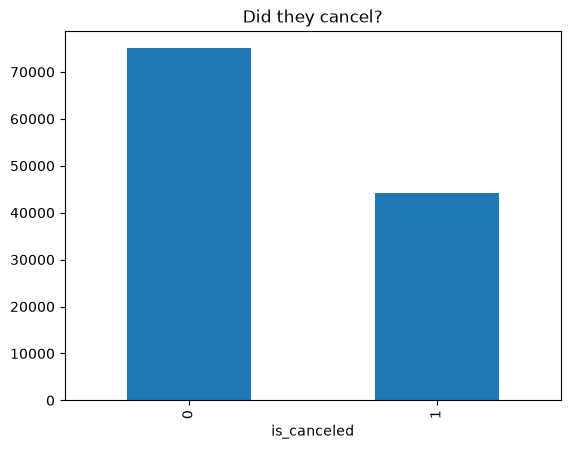

In [12]:
df['is_canceled'].value_counts().plot(kind='bar', title='Did they cancel?')
plt.show()

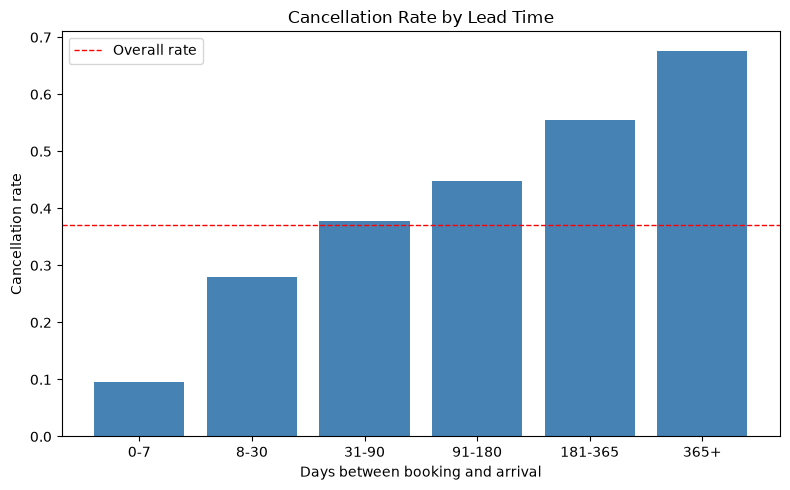

           count  cancel_rate
lead_time                    
0-7        19635        0.096
8-30       18945        0.279
31-90      29529        0.377
91-180     26420        0.447
181-365    21533        0.555
365+        3147        0.677


In [13]:
# Nice visual to show likelihood of cancellation based on how many days
# passed by
lead_bins = pd.cut(df["lead_time"], bins=[-1, 7, 30, 90, 180, 365, 800],
                   labels=["0-7", "8-30", "31-90", "91-180", "181-365",
                           "365+"])
lead_rates = (df.groupby(lead_bins, observed=True)["is_canceled"]
              .agg(count="size", cancel_rate="mean"))
plt.figure(figsize=(8, 5))
plt.bar(lead_rates.index.astype(str), lead_rates["cancel_rate"],
        color="steelblue")
plt.axhline(df["is_canceled"].mean(), color="red", linestyle="--",
            linewidth=1, label="Overall rate")
plt.title("Cancellation Rate by Lead Time")
plt.xlabel("Days between booking and arrival")
plt.ylabel("Cancellation rate")
plt.legend()
plt.tight_layout()
plt.show()
print(lead_rates.round(3))

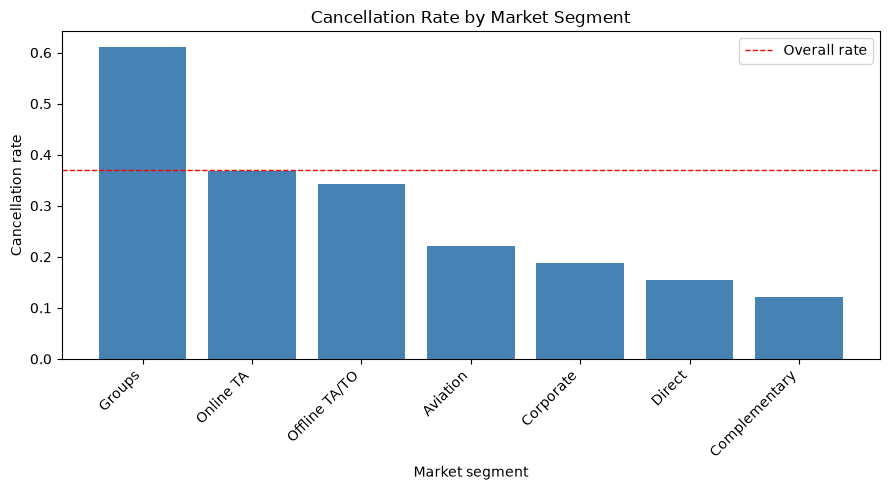

                count  cancel_rate
market_segment                    
Groups          19790        0.611
Online TA       56408        0.368
Offline TA/TO   24182        0.343
Aviation          235        0.221
Corporate        5282        0.188
Direct          12582        0.154
Complementary     728        0.122


In [14]:
seg_rates = (df.groupby("market_segment")["is_canceled"]
             .agg(count="size", cancel_rate="mean")
             .query("count > 100")
             .sort_values("cancel_rate", ascending=False))
plt.figure(figsize=(9, 5))
plt.bar(seg_rates.index, seg_rates["cancel_rate"], color="steelblue")
plt.axhline(df["is_canceled"].mean(), color="red", linestyle="--",
            linewidth=1, label="Overall rate")
plt.title("Cancellation Rate by Market Segment")
plt.xlabel("Market segment")
plt.ylabel("Cancellation rate")
plt.xticks(rotation=45, ha="right")
plt.legend()
plt.tight_layout()
plt.show()
print(seg_rates.round(3))

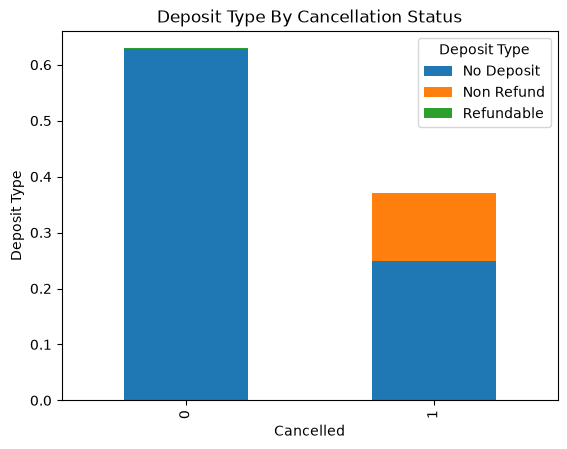

In [15]:
pd.crosstab(df['is_canceled'], df['deposit_type'],
            normalize=True).plot(kind='bar', stacked=True)
plt.title('Deposit Type By Cancellation Status')
plt.xlabel('Cancelled')
plt.ylabel('Deposit Type')
plt.legend(title='Deposit Type')
plt.show()

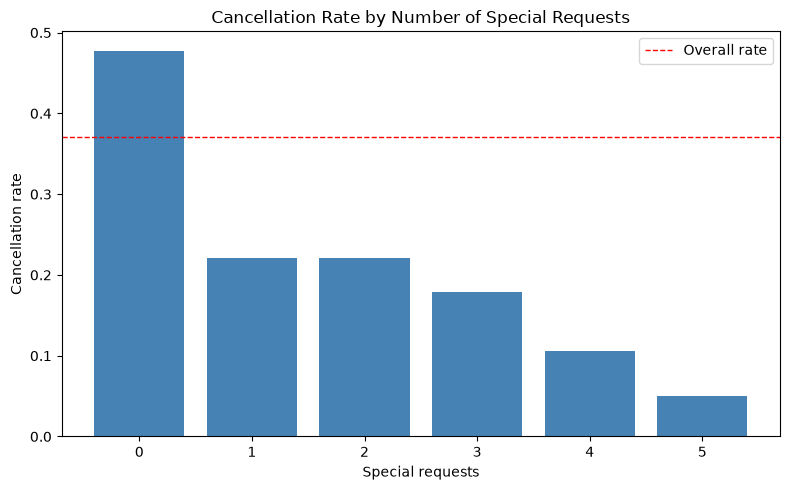

                           count  cancel_rate
total_of_special_requests                    
0                          70200        0.478
1                          33183        0.220
2                          12952        0.221
3                           2494        0.178
4                            340        0.106
5                             40        0.050


In [16]:
req_rates = (df.groupby("total_of_special_requests")["is_canceled"]
             .agg(count="size", cancel_rate="mean"))
plt.figure(figsize=(8, 5))
plt.bar(req_rates.index.astype(str), req_rates["cancel_rate"],
        color="steelblue")
plt.axhline(df["is_canceled"].mean(), color="red", linestyle="--",
            linewidth=1, label="Overall rate")
plt.title("Cancellation Rate by Number of Special Requests")
plt.xlabel("Special requests")
plt.ylabel("Cancellation rate")
plt.legend()
plt.tight_layout()
plt.show()
print(req_rates.round(3))

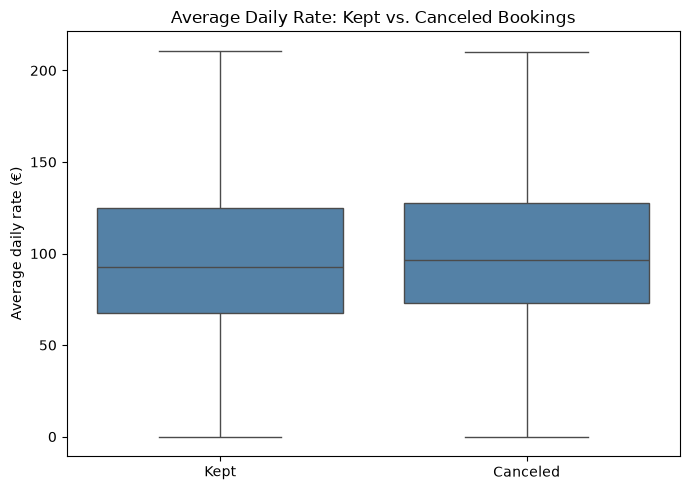

               mean   50%
is_canceled              
0            100.17  92.7
1            105.02  96.3


In [17]:
plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="is_canceled", y="adr", showfliers=False,
            color="steelblue")
plt.xticks([0, 1], ["Kept", "Canceled"])
plt.title("Average Daily Rate: Kept vs. Canceled Bookings")
plt.xlabel("")
plt.ylabel("Average daily rate (€)")
plt.tight_layout()
plt.show()
print(df.groupby("is_canceled")["adr"].describe()[["mean", "50%"]].round(2))

### Feature Engineering

In [18]:
# Dropping week number and day of month, as the information they provide does
# not seem significant enough considering we have arrival_date_year and
# arrival_date_month.
# Dropping reservation_status and reservation_status_date because both of
# these columns directly reveal the target variable is_canceled, and we do
# not want a model that gets the outcome from these two features alone (not
# helpful for the business to improve hotel cancellation rate).
# Dropping required_car_parking_spaces, booking_changes and
# days_in_waiting_list because they are likely recorded after the booking is
# made, so they would leak the outcome.
df = df.drop(columns=['arrival_date_week_number', 'arrival_date_day_of_month',
                      'assigned_room_type', 'reservation_status',
                      'reservation_status_date',
                      'required_car_parking_spaces', 'booking_changes',
                      'days_in_waiting_list'])

df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,...,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,deposit_type,customer_type,adr,total_of_special_requests,booking_group,has_company,has_agent
0,Resort Hotel,0,342,2015,July,0,0,2,0.0,0,...,0,0,C,No Deposit,Transient,0.0,0,79092,0,0
1,Resort Hotel,0,737,2015,July,0,0,2,0.0,0,...,0,0,C,No Deposit,Transient,0.0,0,79419,0,0
2,Resort Hotel,0,7,2015,July,0,1,1,0.0,0,...,0,0,A,No Deposit,Transient,75.0,0,60910,0,0
3,Resort Hotel,0,13,2015,July,0,1,1,0.0,0,...,0,0,A,No Deposit,Transient,75.0,0,62795,0,1
4,Resort Hotel,0,14,2015,July,0,2,2,0.0,0,...,0,0,A,No Deposit,Transient,98.0,1,63017,0,1


In [19]:
df['length_of_stay'] = (df['stays_in_weekend_nights']
                        + df['stays_in_week_nights'])
df[['stays_in_weekend_nights', 'stays_in_week_nights',
    'length_of_stay']].head(30)

,stays_in_weekend_nights,stays_in_week_nights,length_of_stay
0,0,0,0
1,0,0,0
2,0,1,1
3,0,1,1
4,0,2,2
5,0,2,2
6,0,2,2
7,0,2,2
8,0,3,3
9,0,3,3


In [20]:
# For stays_in_weekend_nights and stays_in_week_nights, turn weekend nights
# into a binary feature on whether they stay the weekend or not
df['stays_in_weekend_nights'] = (df['stays_in_weekend_nights'] > 0).astype(int)
df['stays_in_weekend_nights'].value_counts()

# Drop stays_in_week_nights as it is no longer needed (length_of_stay has it)
df = df.drop(columns=['stays_in_week_nights'])
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,stays_in_weekend_nights,adults,children,babies,meal,...,previous_bookings_not_canceled,reserved_room_type,deposit_type,customer_type,adr,total_of_special_requests,booking_group,has_company,has_agent,length_of_stay
0,Resort Hotel,0,342,2015,July,0,2,0.0,0,BB,...,0,C,No Deposit,Transient,0.0,0,79092,0,0,0
1,Resort Hotel,0,737,2015,July,0,2,0.0,0,BB,...,0,C,No Deposit,Transient,0.0,0,79419,0,0,0
2,Resort Hotel,0,7,2015,July,0,1,0.0,0,BB,...,0,A,No Deposit,Transient,75.0,0,60910,0,0,1
3,Resort Hotel,0,13,2015,July,0,1,0.0,0,BB,...,0,A,No Deposit,Transient,75.0,0,62795,0,1,1
4,Resort Hotel,0,14,2015,July,0,2,0.0,0,BB,...,0,A,No Deposit,Transient,98.0,1,63017,0,1,2


In [21]:
# Combine children and babies into one group, since individually they act
# the same (running this code multiple times will change results)
df['children'] = (df['children'] + df['babies']).astype(int)

df = df.drop(columns=['babies'])
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,stays_in_weekend_nights,adults,children,meal,country,...,previous_bookings_not_canceled,reserved_room_type,deposit_type,customer_type,adr,total_of_special_requests,booking_group,has_company,has_agent,length_of_stay
0,Resort Hotel,0,342,2015,July,0,2,0,BB,PRT,...,0,C,No Deposit,Transient,0.0,0,79092,0,0,0
1,Resort Hotel,0,737,2015,July,0,2,0,BB,PRT,...,0,C,No Deposit,Transient,0.0,0,79419,0,0,0
2,Resort Hotel,0,7,2015,July,0,1,0,BB,GBR,...,0,A,No Deposit,Transient,75.0,0,60910,0,0,1
3,Resort Hotel,0,13,2015,July,0,1,0,BB,GBR,...,0,A,No Deposit,Transient,75.0,0,62795,0,1,1
4,Resort Hotel,0,14,2015,July,0,2,0,BB,GBR,...,0,A,No Deposit,Transient,98.0,1,63017,0,1,2


In [22]:
# Keep the 10 most common countries and group the rest as Other, since
# rare countries do not appear in the data set often
top_countries = df["country"].value_counts().nlargest(10).index
df["country"] = df["country"].where(df["country"].isin(top_countries),
                                    "Other")
df.info()

<class 'pandas.DataFrame'>
Index: 119209 entries, 0 to 119389
Data columns (total 24 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119209 non-null  str    
 1   is_canceled                     119209 non-null  int64  
 2   lead_time                       119209 non-null  int64  
 3   arrival_date_year               119209 non-null  int64  
 4   arrival_date_month              119209 non-null  str    
 5   stays_in_weekend_nights         119209 non-null  int64  
 6   adults                          119209 non-null  int64  
 7   children                        119209 non-null  int64  
 8   meal                            119209 non-null  str    
 9   country                         119209 non-null  str    
 10  market_segment                  119209 non-null  str    
 11  distribution_channel            119209 non-null  str    
 12  is_repeated_guest               

Columns like meal, country, reserved_room_type, customer_type, deposit_type  need to be one hot-encoded!

In [23]:
# Leave hotel out of the encoding because we split the data on it
cat_cols = ['arrival_date_month', 'meal', 'country', 'reserved_room_type',
            'customer_type', 'deposit_type', 'market_segment',
            'distribution_channel']
cat_data = df[cat_cols]
cat_encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
cat_feat = pd.DataFrame(cat_encoder.fit_transform(cat_data),
                        columns=cat_encoder.get_feature_names_out(cat_cols),
                        index=cat_data.index)
df = pd.concat([df, cat_feat], axis=1)
df = df.drop(columns=cat_cols)
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,stays_in_weekend_nights,adults,children,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,...,market_segment_Direct,market_segment_Groups,market_segment_Offline TA/TO,market_segment_Online TA,market_segment_Undefined,distribution_channel_Corporate,distribution_channel_Direct,distribution_channel_GDS,distribution_channel_TA/TO,distribution_channel_Undefined
0,Resort Hotel,0,342,2015,0,2,0,0,0,0,...,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
1,Resort Hotel,0,737,2015,0,2,0,0,0,0,...,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
2,Resort Hotel,0,7,2015,0,1,0,0,0,0,...,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
3,Resort Hotel,0,13,2015,0,1,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
4,Resort Hotel,0,14,2015,0,2,0,0,0,0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0


In [24]:
# Split into one table per hotel so each gets its own model
city_hotel = df[df["hotel"] == "City Hotel"].copy()
resort_hotel = df[df["hotel"] == "Resort Hotel"].copy()
print(city_hotel["is_canceled"].mean())
print(resort_hotel["is_canceled"].mean())

0.4178593534858457
0.2776806672326824


City hotel a little more likely to be canceled than resort hotel. 

In [25]:
df.shape

(119209, 73)

In [26]:
# Features: everything except the answer, the hotel name and the booking
# group ID
X_city = city_hotel.drop(columns=['is_canceled', 'hotel', 'booking_group'])
X_resort = resort_hotel.drop(columns=['is_canceled', 'hotel',
                                      'booking_group'])

# Answer: did the booking cancel? (1 = yes, 0 = no)
y_city = city_hotel['is_canceled']
y_resort = resort_hotel['is_canceled']

# Booking group IDs, used only to keep copies of the same booking together
# in the split
groups_city = city_hotel['booking_group']
groups_resort = resort_hotel['booking_group']

In [27]:
# Shared split for every model: 60% train / 20% validation / 20% test per
# hotel. GroupShuffleSplit keeps all copies of a group booking on the same
# side, so no model is scored on an exact copy of a row it trained on.
def group_split(X, y, groups, seed=11):
    outer = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=seed)
    train_valid_idx, test_idx = next(outer.split(X, y, groups))

    inner = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=seed)
    train_idx, valid_idx = next(inner.split(X.iloc[train_valid_idx],
                                            y.iloc[train_valid_idx],
                                            groups.iloc[train_valid_idx]))
    train_idx = train_valid_idx[train_idx]
    valid_idx = train_valid_idx[valid_idx]

    return (X.iloc[train_idx], X.iloc[valid_idx], X.iloc[test_idx],
            y.iloc[train_idx], y.iloc[valid_idx], y.iloc[test_idx])


(X_city_train, X_city_valid, X_city_test,
 y_city_train, y_city_valid, y_city_test) = group_split(X_city, y_city,
                                                        groups_city)
(X_resort_train, X_resort_valid, X_resort_test,
 y_resort_train, y_resort_valid, y_resort_test) = group_split(
    X_resort, y_resort, groups_resort)

print('City   | Train:', len(X_city_train), '| Valid:', len(X_city_valid),
      '| Test:', len(X_city_test), '| Cancel rates:',
      round(y_city_train.mean(), 3), round(y_city_valid.mean(), 3),
      round(y_city_test.mean(), 3))
print('Resort | Train:', len(X_resort_train), '| Valid:',
      len(X_resort_valid), '| Test:', len(X_resort_test), '| Cancel rates:',
      round(y_resort_train.mean(), 3), round(y_resort_valid.mean(), 3),
      round(y_resort_test.mean(), 3))

City   | Train: 47293 | Valid: 15448 | Test: 16422 | Cancel rates: 0.417 0.413 0.426
Resort | Train: 24079 | Valid: 7957 | Test: 8010 | Cancel rates: 0.275 0.279 0.285


In [28]:
# Every model adds its validation scores to `results` so all models land
# in one comparison table
results = []


def evaluate(model_name, hotel, y_true, prob, threshold=0.5):
    """Score predictions at a given cutoff and return one results row."""
    pred = (prob >= threshold).astype(int)
    return {'Model': model_name, 'Hotel': hotel, 'Threshold': threshold,
            'Accuracy': accuracy_score(y_true, pred),
            'Precision': precision_score(y_true, pred),
            'Recall': recall_score(y_true, pred),
            'F1': f1_score(y_true, pred),
            'ROC AUC': roc_auc_score(y_true, prob)}

In [29]:
# Logistic regression for the city hotel
# Scale features
city_scaler = StandardScaler().fit(X_city_train)

# Fit the City model
city_log = LogisticRegression(max_iter=1000)
city_log.fit(city_scaler.transform(X_city_train), y_city_train)

# Predict on the City validation set
X_city_valid_scaled = city_scaler.transform(X_city_valid)
city_valid_pred = city_log.predict(X_city_valid_scaled)
city_valid_prob = city_log.predict_proba(X_city_valid_scaled)[:, 1]

print('Baseline (predict no one cancels): ',
      round(1 - y_city_valid.mean(), 3))
print('Accuracy: ', round(accuracy_score(y_city_valid, city_valid_pred), 3))
print('Precision: ',
      round(precision_score(y_city_valid, city_valid_pred), 3))
print('Recall: ', round(recall_score(y_city_valid, city_valid_pred), 3))
print('ROC AUC: ', round(roc_auc_score(y_city_valid, city_valid_prob), 3))
results.append(evaluate('Logistic Regression', 'City', y_city_valid,
                        city_valid_prob))
confusion_matrix(y_city_valid, city_valid_pred)

Baseline (predict no one cancels):  0.587
Accuracy:  0.797
Precision:  0.819
Recall:  0.652
ROC AUC:  0.871


array([[8153,  920],
       [2221, 4154]])

In [30]:
# Logistic regression for the resort hotel
# Scale features
resort_scaler = StandardScaler().fit(X_resort_train)

# Fit the Resort model
resort_log = LogisticRegression(max_iter=1000)
resort_log.fit(resort_scaler.transform(X_resort_train), y_resort_train)

# Predict on the Resort validation set
X_resort_valid_scaled = resort_scaler.transform(X_resort_valid)
resort_valid_pred = resort_log.predict(X_resort_valid_scaled)
resort_valid_prob = resort_log.predict_proba(X_resort_valid_scaled)[:, 1]

print('Baseline (predict no one cancels): ',
      round(1 - y_resort_valid.mean(), 3))
print('Accuracy: ',
      round(accuracy_score(y_resort_valid, resort_valid_pred), 3))
print('Precision: ',
      round(precision_score(y_resort_valid, resort_valid_pred), 3))
print('Recall: ', round(recall_score(y_resort_valid, resort_valid_pred), 3))
print('ROC AUC: ',
      round(roc_auc_score(y_resort_valid, resort_valid_prob), 3))
results.append(evaluate('Logistic Regression', 'Resort', y_resort_valid,
                        resort_valid_prob))
confusion_matrix(y_resort_valid, resort_valid_pred)

Baseline (predict no one cancels):  0.721
Accuracy:  0.809
Precision:  0.724
Recall:  0.51
ROC AUC:  0.865


array([[5306,  431],
       [1088, 1132]])

In [31]:
# Precision and recall at different cutoffs (validation set only)
city_thresholds = pd.DataFrame([
    {'Threshold': t,
     'Precision': round(precision_score(y_city_valid,
                                        city_valid_prob >= t), 3),
     'Recall': round(recall_score(y_city_valid, city_valid_prob >= t), 3),
     'Bookings flagged': (city_valid_prob >= t).sum()}
    for t in [0.5, 0.6, 0.7, 0.8]
])
city_thresholds

,Threshold,Precision,Recall,Bookings flagged
0,0.5,0.819,0.652,5074
1,0.6,0.883,0.568,4101
2,0.7,0.939,0.486,3298
3,0.8,0.980,0.442,2876


In [32]:
# Same 90% precision target for both hotels: a wrongly flagged booking is
# costly at either one
city_target, resort_target = 0.90, 0.90


def pick_threshold(y_valid, valid_prob, target):
    """Return the lowest cutoff that reaches the precision target."""
    for t in np.arange(0.30, 0.96, 0.01):
        if precision_score(y_valid, valid_prob >= t) >= target:
            return round(t, 2)


city_threshold = pick_threshold(y_city_valid, city_valid_prob, city_target)
resort_threshold = pick_threshold(y_resort_valid, resort_valid_prob,
                                  resort_target)

results.append(evaluate('Logistic Regression (tuned cutoff)', 'City',
                        y_city_valid, city_valid_prob, city_threshold))
results.append(evaluate('Logistic Regression (tuned cutoff)', 'Resort',
                        y_resort_valid, resort_valid_prob, resort_threshold))
pd.DataFrame(results).round(3)

,Model,Hotel,Threshold,Accuracy,Precision,Recall,F1,ROC AUC
0,Logistic Regression,City,0.50,0.797,0.819,0.652,0.726,0.871
1,Logistic Regression,Resort,0.50,0.809,0.724,0.510,0.598,0.865
2,Logistic Regression (tuned cutoff),City,0.63,0.789,0.903,0.546,0.681,0.871
3,Logistic Regression (tuned cutoff),Resort,0.83,0.777,0.902,0.224,0.359,0.865


# Logistic Regression Takeaway
For both City and Resort hotels a False Positive, a reservation flagged as a cancellation when they did not end up canceling, is more costly than False Negative. What that means for modeling is we want to favor Precision over Recall, the reason being is if a hotel overbooks they risk a bad review, having to pay for customers stay plus travel expenses, bad review etc. On the other hand if a hotel misses a cancellation worst case they miss out on the adr(average daily rate) on their establishment... less costly than flagging somekone as cancelled and they not cancel.

The two hotels don't behave the same way, though. At the City Hotel, a cutoff of 0.63 reaches 90% precision while still catching about 55% of cancellations, so the model is reliable enough to support overbooking decisions. The Resort Hotel needs a cutoff of 0.83 to reach that same 90% precision, and at that point it only catches about 22% of cancellations. The Resort model still ranks bookings well (AUC 0.865), but very few of its bookings get high-confidence predictions, which suggests Resort cancellations are harder to see coming from booking details alone, likely because they're driven more by individual leisure travelers changing plans than by group or agency bookings. We still hold the Resort to the same 90% target, because wrongly flagging a booking is just as costly there. The low recall is the finding: the Resort model should only act on the small number of bookings it is very confident about.


### Naive Bayes (Brandon)

#### Why Naive Bayes

I used Naive Bayes as a fast, simple baseline. It trains in seconds and is easy to explain, since each feature's effect comes down to how often it shows up in cancelled bookings versus kept ones, which makes it a good check on how much the more complex models actually add. I used 'CategoricalNB', which only works with categories, so I binned the number columns first. Lead time uses the same groups as the EDA chart (0–7, 8–30, 31–90, 91–180, 181–365, and 365+ days), and length of stay is grouped into 0–2, 3–4, 5–7, and 8+ nights. I split adr into low, medium, and high thirds as the team agreed, and calculated the cutoffs on the training set only so no validation or test data leaks into the model. I also capped the count columns (adults at 3, children at 2, previous cancellations and previous bookings at 1, and special requests at 3), since higher values are rare and would otherwise each get their own category. Like the other models, it uses the shared group split (60/20/20 per hotel, duplicates kept), is scored on the validation set, and is held to the team's 90% precision target.

In [33]:
def bin_features(data):
    # Naive Bayes only works with categories, so the number columns need to
    # be grouped into bins
    data = data.copy()  # work on a copy so the shared data doesn't change

    # Lead time uses the same groups as the EDA chart (0-7, 8-30, 31-90,
    # 91-180, 181-365, and 365+ days)
    data["lead_time"] = pd.cut(data["lead_time"],
                               bins=[-1, 7, 30, 90, 180, 365, 800],
                               labels=False)

    # Length of stay is split into 0-2, 3-4, 5-7, and 8+ nights
    data["length_of_stay"] = pd.cut(data["length_of_stay"],
                                    bins=[-1, 2, 4, 7, 100], labels=False)

    # Rare high values are grouped together so they don't each get their
    # own category
    data["adults"] = data["adults"].clip(upper=3)
    data["children"] = data["children"].clip(upper=2)
    data["previous_cancellations"] = (
        data["previous_cancellations"].clip(upper=1))
    data["previous_bookings_not_canceled"] = (
        data["previous_bookings_not_canceled"].clip(upper=1))
    data["total_of_special_requests"] = (
        data["total_of_special_requests"].clip(upper=3))

    # The years 2015, 2016, and 2017 become 0, 1, and 2
    data["arrival_date_year"] = data["arrival_date_year"] - 2015
    return data


def bin_adr(X_train, X_valid, X_test):
    # Price is split into thirds: 0 = low, 1 = medium, 2 = high
    low = X_train["adr"].quantile(1/3)
    high = X_train["adr"].quantile(2/3)
    bins = [-np.inf, low, high, np.inf]

    X_train["adr"] = pd.cut(X_train["adr"], bins, labels=False)
    X_valid["adr"] = pd.cut(X_valid["adr"], bins, labels=False)
    X_test["adr"] = pd.cut(X_test["adr"], bins, labels=False)

    print("adr cutoffs: low is under", round(low, 2),
          "euros and high is over", round(high, 2), "euros")
    return X_train, X_valid, X_test

In [34]:
def fit_naive_bayes(X_train, X_valid, X_test, y_train):
    # Bin the train, validation, and test sets the same way
    X_train = bin_features(X_train)
    X_valid = bin_features(X_valid)
    X_test = bin_features(X_test)
    X_train, X_valid, X_test = bin_adr(X_train, X_valid, X_test)

    X_train = X_train.astype(int)
    X_valid = X_valid.astype(int)
    X_test = X_test.astype(int)

    # Tell the model how many groups each column has, so it doesn't break if
    # a rare group shows up in validation or test but not in training
    all_rows = pd.concat([X_train, X_valid, X_test])
    n_categories = all_rows.max().values + 1

    # Train the model on the training set only
    model = CategoricalNB(min_categories=n_categories)
    model.fit(X_train, y_train)
    return model, X_valid, X_test


# One model for each hotel
nb_city, nb_X_city_valid, nb_X_city_test = fit_naive_bayes(
    X_city_train, X_city_valid, X_city_test, y_city_train)
nb_resort, nb_X_resort_valid, nb_X_resort_test = fit_naive_bayes(
    X_resort_train, X_resort_valid, X_resort_test, y_resort_train)

adr cutoffs: low is under 87.0 euros and high is over 115.84 euros
adr cutoffs: low is under 58.5 euros and high is over 102.65 euros


Baseline (predict no one cancels):  0.587
Accuracy:  0.765
Precision:  0.859
Recall:  0.516
ROC AUC:  0.822


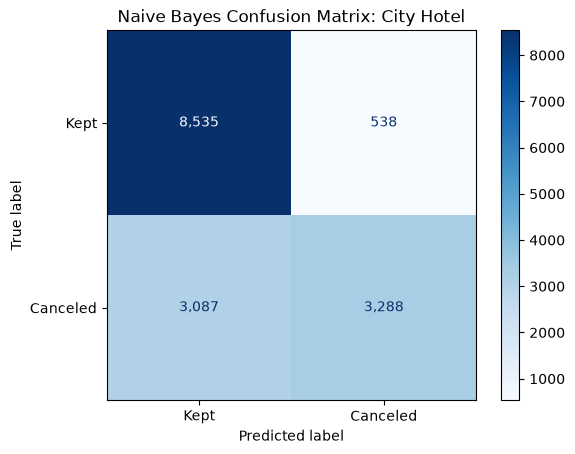

In [35]:
# Removing any old Naive Bayes rows first to make results table cleaner
results = [row for row in results
           if not row['Model'].startswith('Naive Bayes')]

# City Hotel: chance of cancellation for each validation booking
nb_city_valid_prob = nb_city.predict_proba(nb_X_city_valid)[:, 1]

# Anything at 50% or higher is predicted as a cancellation
nb_city_valid_pred = (nb_city_valid_prob >= 0.5).astype(int)

print('Baseline (predict no one cancels): ',
      round(1 - y_city_valid.mean(), 3))
print('Accuracy: ',
      round(accuracy_score(y_city_valid, nb_city_valid_pred), 3))
print('Precision: ',
      round(precision_score(y_city_valid, nb_city_valid_pred), 3))
print('Recall: ', round(recall_score(y_city_valid, nb_city_valid_pred), 3))
print('ROC AUC: ',
      round(roc_auc_score(y_city_valid, nb_city_valid_prob), 3))

# Adding the scores to the shared results table
results.append(evaluate('Naive Bayes', 'City', y_city_valid,
                        nb_city_valid_prob))

# Confusion matrix
ConfusionMatrixDisplay(confusion_matrix(y_city_valid, nb_city_valid_pred),
                       display_labels=["Kept", "Canceled"]).plot(
    cmap="Blues", values_format=",")
plt.title("Naive Bayes Confusion Matrix: City Hotel")
plt.show()

Baseline (predict no one cancels):  0.721
Accuracy:  0.8
Precision:  0.66
Recall:  0.582
ROC AUC:  0.832


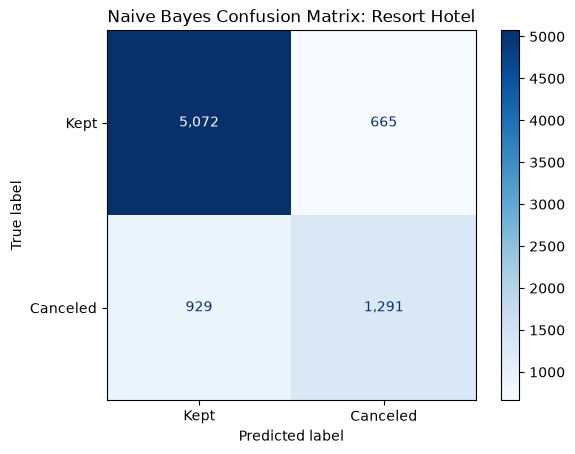

In [36]:
# Resort Hotel: chance of cancellation for each validation booking
nb_resort_valid_prob = nb_resort.predict_proba(nb_X_resort_valid)[:, 1]

# Anything at 50% or higher is predicted as a cancellation
nb_resort_valid_pred = (nb_resort_valid_prob >= 0.5).astype(int)

print('Baseline (predict no one cancels): ',
      round(1 - y_resort_valid.mean(), 3))
print('Accuracy: ',
      round(accuracy_score(y_resort_valid, nb_resort_valid_pred), 3))
print('Precision: ',
      round(precision_score(y_resort_valid, nb_resort_valid_pred), 3))
print('Recall: ',
      round(recall_score(y_resort_valid, nb_resort_valid_pred), 3))
print('ROC AUC: ',
      round(roc_auc_score(y_resort_valid, nb_resort_valid_prob), 3))

# Adding the scores to the shared results table
results.append(evaluate('Naive Bayes', 'Resort', y_resort_valid,
                        nb_resort_valid_prob))

# Confusion matrix
ConfusionMatrixDisplay(confusion_matrix(y_resort_valid, nb_resort_valid_pred),
                       display_labels=["Kept", "Canceled"]).plot(
    cmap="Blues", values_format=",")
plt.title("Naive Bayes Confusion Matrix: Resort Hotel")
plt.show()

In [37]:
# Find the cutoff that reaches the team's 90% precision target, using
# pick_threshold from above
nb_city_threshold = pick_threshold(y_city_valid, nb_city_valid_prob,
                                   city_target)
nb_resort_threshold = pick_threshold(y_resort_valid, nb_resort_valid_prob,
                                     resort_target)
print('City cutoff:', nb_city_threshold, '| Resort cutoff:',
      nb_resort_threshold)

# If a hotel never reaches 90% precision, pick_threshold gives back None, so
# that hotel is skipped
if nb_city_threshold is not None:
    results.append(evaluate('Naive Bayes (tuned cutoff)', 'City',
                            y_city_valid, nb_city_valid_prob,
                            nb_city_threshold))
if nb_resort_threshold is not None:
    results.append(evaluate('Naive Bayes (tuned cutoff)', 'Resort',
                            y_resort_valid, nb_resort_valid_prob,
                            nb_resort_threshold))

pd.DataFrame(results).round(3)

City cutoff: 0.69 | Resort cutoff: None


,Model,Hotel,Threshold,Accuracy,Precision,Recall,F1,ROC AUC
0,Logistic Regression,City,0.50,0.797,0.819,0.652,0.726,0.871
1,Logistic Regression,Resort,0.50,0.809,0.724,0.510,0.598,0.865
2,Logistic Regression (tuned cutoff),City,0.63,0.789,0.903,0.546,0.681,0.871
3,Logistic Regression (tuned cutoff),Resort,0.83,0.777,0.902,0.224,0.359,0.865
4,Naive Bayes,City,0.50,0.765,0.859,0.516,0.645,0.822
5,Naive Bayes,Resort,0.50,0.800,0.660,0.582,0.618,0.832
6,Naive Bayes (tuned cutoff),City,0.69,0.761,0.902,0.473,0.621,0.822


In [38]:
# Resort never reaches 90% precision between 0.30 and 0.95, so check a much
# higher cutoff
resort_high = nb_resort_valid_prob >= 0.99
precision_99 = round(precision_score(y_resort_valid, resort_high) * 100, 1)
recall_99 = round(recall_score(y_resort_valid, resort_high) * 100, 1)
caught_99 = (resort_high & (y_resort_valid == 1)).sum()

print('At a 0.99 cutoff, the Resort model flags', resort_high.sum(),
      'bookings as likely to cancel.')
print(precision_99, '% of those actually canceled, but that only catches',
      caught_99, 'of', y_resort_valid.sum(), 'cancellations (', recall_99,
      '%).')

At a 0.99 cutoff, the Resort model flags 249 bookings as likely to cancel.
90.4 % of those actually canceled, but that only catches 225 of 2220 cancellations ( 10.1 %).


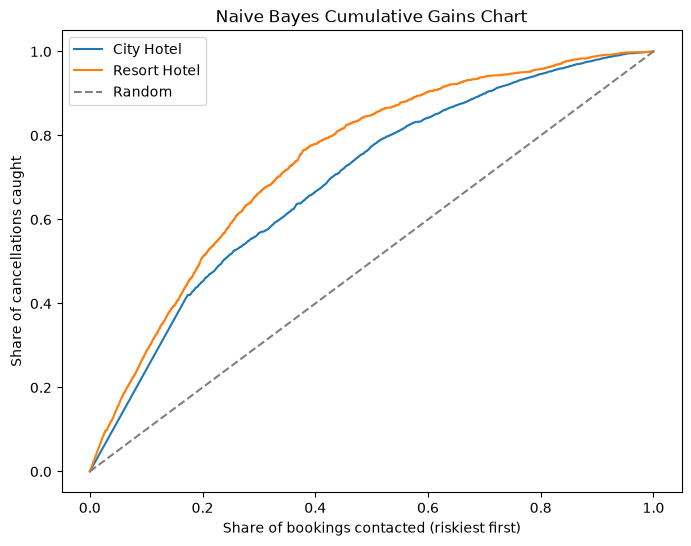

In [39]:
# Cumulative gains chart: if the hotel contacts the riskiest bookings first,
# how many of the cancellations would it catch compared to picking bookings
# at random?
def plot_gains(y_true, prob, label):
    # Sort bookings from riskiest to safest
    order = np.argsort(-prob)
    # Share of cancellations caught so far
    caught = np.cumsum(y_true.values[order]) / y_true.sum()
    # Share of bookings contacted so far
    contacted = np.arange(1, len(prob) + 1) / len(prob)
    plt.plot(contacted, caught, label=label)


plt.figure(figsize=(8, 6))
plot_gains(y_city_valid, nb_city_valid_prob, "City Hotel")
plot_gains(y_resort_valid, nb_resort_valid_prob, "Resort Hotel")
plt.plot([0, 1], [0, 1], color="gray", linestyle="--", label="Random")
plt.title("Naive Bayes Cumulative Gains Chart")
plt.xlabel("Share of bookings contacted (riskiest first)")
plt.ylabel("Share of cancellations caught")
plt.legend()
plt.show()

In [40]:
# Share of cancellations caught if the hotel contacts the riskiest 20% of
# bookings
for name, y_true, prob in [('City', y_city_valid, nb_city_valid_prob),
                           ('Resort', y_resort_valid, nb_resort_valid_prob)]:
    top_20 = prob >= np.quantile(prob, 0.80)
    caught = round(y_true[top_20].sum() / y_true.sum() * 100, 1)
    print(name, 'Hotel: contacting the riskiest 20% of bookings catches',
          caught, '% of cancellations.')

City Hotel: contacting the riskiest 20% of bookings catches 45.2 % of cancellations.
Resort Hotel: contacting the riskiest 20% of bookings catches 51.1 % of cancellations.


The gains chart shows how well the model ranks bookings by risk. If the hotel contacted bookings at random, it would catch cancellations at the same rate it contacts guests, which is the gray dashed line. Contacting the riskiest 20% of bookings first catches about 45% of cancellations at the City Hotel and about 51% at the Resort Hotel, so either hotel can focus its follow-up calls or overbooking decisions on a small group of bookings and still catch a large share of the cancellations. The City number is actually the stronger result, though. About 41% of City bookings cancel, so even a perfect model could only catch about 48% of cancellations by contacting 20% of bookings, and the model gets close to that. At the Resort, where only 28% of bookings cancel, the best possible is about 72%, so there is more room to improve. Both curves stay well above the random line, which means the model is useful for ranking bookings by risk even at the Resort, where it couldn't reach the 90% precision target.

# Naive Bayes Takeaway

At the default 0.5 cutoff, Naive Bayes beat the baseline at both hotels. At the City Hotel, accuracy was 76.5% compared to 58.7% from predicting that no one cancels, and when the model flagged a booking it was right 85.9% of the time, but it only caught 51.6% of cancellations. The Resort Hotel went the other way: the model caught more cancellations (58.2%), but only 66.0% of its flags were correct. Its AUC was 0.822 at the City Hotel and 0.832 at the Resort, which is lower than logistic regression (0.871 and 0.865) and the neural network, so it ranks risky bookings less well than both.

At the City Hotel, Naive Bayes reaches the team's 90% precision target at a 0.69 cutoff, but it only catches 47.3% of cancellations, compared to 54.6% for logistic regression at the same precision. At the Resort Hotel, it never reaches 90% precision between 0.30 and 0.95. It only gets there at a 0.99 cutoff, where it catches 10.1% of cancellations from just 249 flagged bookings, which is too few to be useful for overbooking decisions. Even so, the gains chart shows the model still ranks Resort bookings well above random, so it could still help decide which guests to contact first, just not which rooms to overbook.

Keeping the duplicates mattered for this model. Most duplicate rows are group bookings, which is also why non-refundable deposits show such a high cancellation rate. When I compared this version to an earlier one with duplicates removed, keeping them made the model's flags more accurate but it caught fewer cancellations overall. It picks up group cancellations well but misses more individual ones.

The main limitation is that Naive Bayes assumes every feature is independent once you know whether the booking canceled, which isn't true here. Market segment and distribution channel overlap heavily, for example, so the model counts the same signal twice and its probabilities come out too extreme, which is likely why the Resort scores pile up near 0 and 1. Binning also throws away detail, since a booking made 91 days ahead and one made 180 days ahead look the same to the model. I chose the cutoffs on the validation set, so these numbers may be a little optimistic, and all results come from one split.

For next steps, I would tune the smoothing parameter (alpha) on the validation set, drop one of each pair of overlapping features like distribution channel, and try narrower lead time bins. Overall, Naive Bayes works as a fast, easy-to-explain baseline, but it shouldn't be the model the hotels use, since logistic regression and the neural network both catch more cancellations at the same precision.

### Neural Network (Samuel)

In [41]:
# Neural network (MLP) for each hotel, tuned with a grid search.
# Features are already one-hot encoded, so the pipeline only needs to scale
# them. The scaler sits inside the pipeline so it is re-fit on each CV fold
# (no leakage). GroupKFold keeps copies of the same booking in the same fold,
# matching the shared split.

# Some sgd settings in the grid stop at max_iter before converging; hide
# those warnings to keep the output readable
warnings.filterwarnings('ignore', category=ConvergenceWarning)

nn_param_grid = {
    'net__hidden_layer_sizes': [(5,), (10,), (20,)],
    'net__activation': ['tanh', 'relu'],
    'net__solver': ['adam', 'sgd']
}


def fit_nn(X_train, y_train, groups_train):
    """Grid-search an MLP on the training rows only."""
    pipe = Pipeline([
        ('scale', StandardScaler()),
        ('net', MLPClassifier(random_state=11, max_iter=300))
    ])
    search = GridSearchCV(pipe, nn_param_grid, cv=GroupKFold(n_splits=5),
                          scoring='roc_auc', n_jobs=-1)
    search.fit(X_train, y_train, groups=groups_train)
    return search


nn_city = fit_nn(X_city_train, y_city_train,
                 groups_city.loc[X_city_train.index])
nn_resort = fit_nn(X_resort_train, y_resort_train,
                   groups_resort.loc[X_resort_train.index])

print('City best params:  ', nn_city.best_params_, '| CV AUC:',
      round(nn_city.best_score_, 3))
print('Resort best params:', nn_resort.best_params_, '| CV AUC:',
      round(nn_resort.best_score_, 3))

City best params:   {'net__activation': 'relu', 'net__hidden_layer_sizes': (20,), 'net__solver': 'adam'} | CV AUC: 0.907
Resort best params: {'net__activation': 'relu', 'net__hidden_layer_sizes': (10,), 'net__solver': 'adam'} | CV AUC: 0.911


In [42]:
# Neural network scores on the validation set (default 0.5 cutoff), City
nn_city_valid_prob = nn_city.predict_proba(X_city_valid)[:, 1]
nn_city_valid_pred = (nn_city_valid_prob >= 0.5).astype(int)

print('Baseline (predict no one cancels): ',
      round(1 - y_city_valid.mean(), 3))
print('Accuracy: ',
      round(accuracy_score(y_city_valid, nn_city_valid_pred), 3))
print('Precision: ',
      round(precision_score(y_city_valid, nn_city_valid_pred), 3))
print('Recall: ', round(recall_score(y_city_valid, nn_city_valid_pred), 3))
print('ROC AUC: ',
      round(roc_auc_score(y_city_valid, nn_city_valid_prob), 3))
results.append(evaluate('Neural Network', 'City', y_city_valid,
                        nn_city_valid_prob))
confusion_matrix(y_city_valid, nn_city_valid_pred)

Baseline (predict no one cancels):  0.587
Accuracy:  0.832
Precision:  0.821
Recall:  0.758
ROC AUC:  0.91


array([[8021, 1052],
       [1544, 4831]])

In [43]:
# Neural network scores on the validation set (default 0.5 cutoff), Resort
nn_resort_valid_prob = nn_resort.predict_proba(X_resort_valid)[:, 1]
nn_resort_valid_pred = (nn_resort_valid_prob >= 0.5).astype(int)

print('Baseline (predict no one cancels): ',
      round(1 - y_resort_valid.mean(), 3))
print('Accuracy: ',
      round(accuracy_score(y_resort_valid, nn_resort_valid_pred), 3))
print('Precision: ',
      round(precision_score(y_resort_valid, nn_resort_valid_pred), 3))
print('Recall: ',
      round(recall_score(y_resort_valid, nn_resort_valid_pred), 3))
print('ROC AUC: ',
      round(roc_auc_score(y_resort_valid, nn_resort_valid_prob), 3))
results.append(evaluate('Neural Network', 'Resort', y_resort_valid,
                        nn_resort_valid_prob))
confusion_matrix(y_resort_valid, nn_resort_valid_pred)

Baseline (predict no one cancels):  0.721
Accuracy:  0.848
Precision:  0.766
Recall:  0.655
ROC AUC:  0.908


array([[5294,  443],
       [ 766, 1454]])

In [44]:
# Tuned cutoff: same 90% precision target used for Logistic Regression
# (pick_threshold is defined above)
nn_city_threshold = pick_threshold(y_city_valid, nn_city_valid_prob,
                                   city_target)
nn_resort_threshold = pick_threshold(y_resort_valid, nn_resort_valid_prob,
                                     resort_target)
print('City cutoff:', nn_city_threshold, '| Resort cutoff:',
      nn_resort_threshold)

# pick_threshold returns None if the 90% target is never reached, so only
# score hotels that reached it
if nn_city_threshold is not None:
    results.append(evaluate('Neural Network (tuned cutoff)', 'City',
                            y_city_valid, nn_city_valid_prob,
                            nn_city_threshold))
if nn_resort_threshold is not None:
    results.append(evaluate('Neural Network (tuned cutoff)', 'Resort',
                            y_resort_valid, nn_resort_valid_prob,
                            nn_resort_threshold))

pd.DataFrame(results).round(3)

City cutoff: 0.7 | Resort cutoff: 0.84


,Model,Hotel,Threshold,Accuracy,Precision,Recall,F1,ROC AUC
0,Logistic Regression,City,0.50,0.797,0.819,0.652,0.726,0.871
1,Logistic Regression,Resort,0.50,0.809,0.724,0.510,0.598,0.865
2,Logistic Regression (tuned cutoff),City,0.63,0.789,0.903,0.546,0.681,0.871
3,Logistic Regression (tuned cutoff),Resort,0.83,0.777,0.902,0.224,0.359,0.865
4,Naive Bayes,City,0.50,0.765,0.859,0.516,0.645,0.822
5,Naive Bayes,Resort,0.50,0.800,0.660,0.582,0.618,0.832
6,Naive Bayes (tuned cutoff),City,0.69,0.761,0.902,0.473,0.621,0.822
7,Neural Network,City,0.50,0.832,0.821,0.758,0.788,0.910
8,Neural Network,Resort,0.50,0.848,0.766,0.655,0.706,0.908
9,Neural Network (tuned cutoff),City,0.70,0.816,0.904,0.619,0.735,0.910


### Model Comparison (Validation Set)

In [45]:
# All models side by side on the same validation rows
(pd.DataFrame(results)
 .sort_values(['Hotel', 'Precision'], ascending=[True, False])
 .round(3))

,Model,Hotel,Threshold,Accuracy,Precision,Recall,F1,ROC AUC
9,Neural Network (tuned cutoff),City,0.70,0.816,0.904,0.619,0.735,0.910
2,Logistic Regression (tuned cutoff),City,0.63,0.789,0.903,0.546,0.681,0.871
6,Naive Bayes (tuned cutoff),City,0.69,0.761,0.902,0.473,0.621,0.822
4,Naive Bayes,City,0.50,0.765,0.859,0.516,0.645,0.822
7,Neural Network,City,0.50,0.832,0.821,0.758,0.788,0.910
0,Logistic Regression,City,0.50,0.797,0.819,0.652,0.726,0.871
3,Logistic Regression (tuned cutoff),Resort,0.83,0.777,0.902,0.224,0.359,0.865
10,Neural Network (tuned cutoff),Resort,0.84,0.802,0.900,0.326,0.478,0.908
8,Neural Network,Resort,0.50,0.848,0.766,0.655,0.706,0.908
1,Logistic Regression,Resort,0.50,0.809,0.724,0.510,0.598,0.865


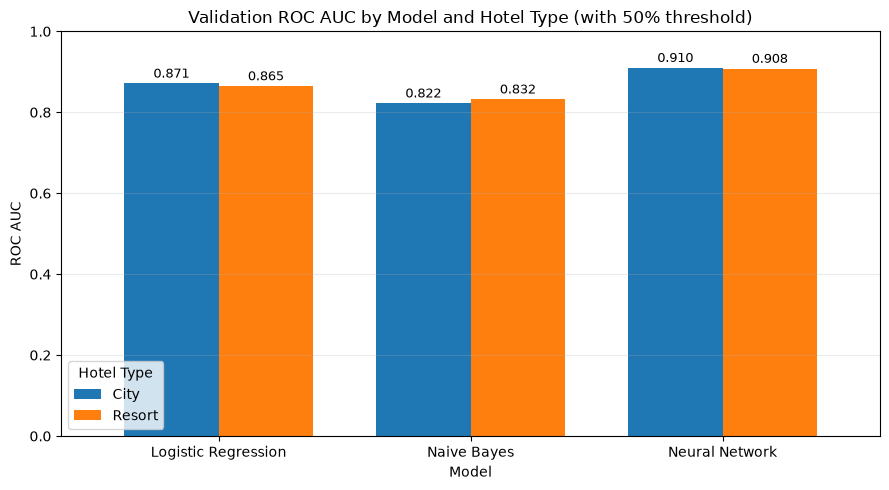

In [46]:
comparison_df = pd.DataFrame(results)
default_models = ['Logistic Regression', 'Naive Bayes', 'Neural Network']
auc_df = comparison_df[
    comparison_df['Model'].isin(default_models)
    & np.isclose(comparison_df['Threshold'].astype(float), 0.50)
].copy()

# Put model names on the x-axis and City/Resort ROC AUC values side by side
auc_pivot = auc_df.pivot_table(index='Model', columns='Hotel',
                               values='ROC AUC', aggfunc='first')
auc_pivot = auc_pivot.reindex(default_models)
ax = auc_pivot.plot(kind='bar', figsize=(9, 5), width=0.75)
ax.set_title('Validation ROC AUC by Model and Hotel Type '
             '(with 50% threshold)')
ax.set_xlabel('Model')
ax.set_ylabel('ROC AUC')
ax.set_ylim(0, 1)
ax.legend(title='Hotel Type')
ax.tick_params(axis='x', rotation=0)
ax.grid(axis='y', alpha=0.25)

# Label each bar with its ROC AUC value
for container in ax.containers:
    ax.bar_label(container, fmt='%.3f', padding=2, fontsize=9)

plt.tight_layout()
plt.show()

## Neural Network Analysis

The Neural Network like the other technical models used separate models trained for City Hotel and Resort Hotel. Grid search with cross-validation was used to identify the best hyperparameters based on ROC AUC. The best configurations for both hotel types used the ReLU activation function and the Adam optimizer. The City Hotel model selected one hidden layer with 20 neurons, while the Resort Hotel model selected one hidden layer with 10 neurons.
Precision and ROC AUC are useful metrics for assessing how well the models identify cancellation risk. Precision measures the proportion of bookings flagged as likely to cancel that actually cancel. ROC AUC measures the model's ability to distinguish cancellations from non-cancellations across different classification thresholds. For City Hotel, 82.1% precision means that approximately 82 out of every 100 bookings flagged as likely to cancel actually canceled. For Resort Hotel, 76.6% precision means approximately 77 out of every 100 flagged bookings canceled. These predictions could help hotel workers prioritize follow-up on higher-risk bookings, allowing them to focus their resources more efficiently. The tuned neural network demonstrated strong cancellation-prediction performance for both City Hotel and Resort Hotel. City Hotel showed stronger precision and recall, while Resort Hotel achieved slightly higher accuracy. These results support further evaluation of neural networks as a tool for identifying potentially canceled bookings. Due to the strong overall metrics the Neural network model shows that it can be the most effective model of choice for helping the hotel business out directly. Despite its strong performance, the neural network has limitations. Training and hyperparameter optimization can be computationally expensive, and the model is often considered a black box because its predictions are more difficult to interpret than those of simpler models. Although the model can learn complex patterns in booking data, explaining exactly why it predicts an individual booking will cancel can be challenging. Future work could explore a neural network architecture tailored to each hotel's booking patterns and business needs. Additional experimentation with building a company catered neural net architecture and hyperparameter tuning may improve ROC AUC and precision metrics. 

### Final Model on Test Set

In [47]:
nn_city_test_prob = nn_city.predict_proba(X_city_test)[:, 1]
nn_resort_test_prob = nn_resort.predict_proba(X_resort_test)[:, 1]

# Final test scores at the cutoffs chosen on validation (do not re-tune on
# test)
final_results = pd.DataFrame([
    evaluate('Neural Network (tuned cutoff)', 'City', y_city_test,
             nn_city_test_prob, nn_city_threshold),
    evaluate('Neural Network (tuned cutoff)', 'Resort', y_resort_test,
             nn_resort_test_prob, nn_resort_threshold),
    evaluate('Neural Network (default 0.5)', 'City', y_city_test,
             nn_city_test_prob, 0.5),
    evaluate('Neural Network (default 0.5)', 'Resort', y_resort_test,
             nn_resort_test_prob, 0.5),
]).round(3)
display(final_results)

print('CITY')
print(confusion_matrix(
    y_city_test, (nn_city_test_prob >= nn_city_threshold).astype(int)))
print('RESORT')
print(confusion_matrix(
    y_resort_test, (nn_resort_test_prob >= nn_resort_threshold).astype(int)))

,Model,Hotel,Threshold,Accuracy,Precision,Recall,F1,ROC AUC
0,Neural Network (tuned cutoff),City,0.70,0.832,0.927,0.658,0.770,0.92
1,Neural Network (tuned cutoff),Resort,0.84,0.815,0.929,0.380,0.539,0.91
2,Neural Network (default 0.5),City,0.50,0.832,0.826,0.767,0.796,0.92
3,Neural Network (default 0.5),Resort,0.50,0.847,0.765,0.668,0.714,0.91


CITY
[[9066  360]
 [2391 4605]]
RESORT
[[5665   66]
 [1414  865]]


## Model Brief (Draft)

**What we tried.** We built three models for each hotel: logistic regression as an easy-to-explain baseline, Naive Bayes as a fast baseline, and a neural network to see if a more flexible model could pick up patterns the others miss. Every model used the same cleaned data, the same features, and the same split, so the comparison is fair.

**Key decisions.**
- We kept the duplicate rows because most of them are group bookings (several identical rooms booked together), and those cancel at a much higher rate. To keep this from inflating our scores, we split the data with GroupShuffleSplit so every copy of a booking lands on the same side of the 60/20/20 train/validation/test split.
- We dropped reservation_status and reservation_status_date, plus required_car_parking_spaces, booking_changes and days_in_waiting_list, because they are recorded after the booking and would leak the answer.
- We built separate models for the City and Resort hotels since their cancellation patterns are different.
- We tuned for precision instead of accuracy. If the hotel overbooks a room for a guest who then shows up, it pays for another hotel and risks a bad review, which costs more than missing a cancellation. Each model's cutoff was picked on the validation set to reach 90% precision.

**What each approach showed.** At 90% precision on validation, logistic regression caught 54.6% of City cancellations and 22.4% of Resort cancellations. Naive Bayes caught 47.3% at the City Hotel and never reached 90% precision at the Resort. The neural network did best at both hotels, catching 61.9% at the City Hotel and 32.6% at the Resort, with the highest ROC AUC (0.910 City, 0.908 Resort). We chose the neural network as our final model. On the test set it reached 92.7% precision and 65.8% recall at the City Hotel, and 92.9% precision and 38.0% recall at the Resort.

**Known limitations.** Resort cancellations are much harder to predict with confidence, so at 90% precision the model only catches a small share of them, which makes it better for low-cost actions than for overbooking. The neural network's grid search tuned for ROC AUC, and precision was handled afterward through the cutoff. All results come from one split of data from two hotels between 2015 and 2017, and the cutoffs were chosen on validation, so real-world results may be a little lower.

**Next steps.** Test the model on newer booking data, tune the neural network directly for precision, try other models like random forests or gradient boosting, and look for data that could explain Resort cancellations, like price changes after booking.